In [1]:
# CELDA 1: Instalación de dependencias necesarias
!pip install -q diffusers transformers accelerate peft datasets
!pip uninstall -y torchao -q

In [2]:
# CELDA 2: Carga de modelos base (VAE, Text Encoder, Tokenizer y U-Net)
import torch
import torch.nn.functional as F
from diffusers import StableDiffusionPipeline, DDPMScheduler, AutoencoderKL, UNet2DConditionModel
from transformers import CLIPTextModel, CLIPTokenizer
from peft import LoraConfig, get_peft_model
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import os

device = "cuda" if torch.cuda.is_available() else "cpu"
model_id = "runwayml/stable-diffusion-v1-5"

tokenizer = CLIPTokenizer.from_pretrained(model_id, subfolder="tokenizer")
text_encoder = CLIPTextModel.from_pretrained(model_id, subfolder="text_encoder").to(device)
vae = AutoencoderKL.from_pretrained(model_id, subfolder="vae").to(device)
unet = UNet2DConditionModel.from_pretrained(model_id, subfolder="unet").to(device)
noise_scheduler = DDPMScheduler.from_pretrained(model_id, subfolder="scheduler")

# Congelar VAE y Text Encoder para ahorrar VRAM
vae.requires_grad_(False)
text_encoder.requires_grad_(False)

# Configurar LoRA en la U-Net (Fine-Tuning eficiente en parámetros)
lora_config = LoraConfig(
    r=4,
    lora_alpha=4,
    init_lora_weights="gaussian",
    target_modules=["to_k", "to_q", "to_v", "to_out.0"],
)
unet = get_peft_model(unet, lora_config)
unet.print_trainable_parameters()

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


trainable params: 797,184 || all params: 860,318,148 || trainable%: 0.0927


In [3]:
# CELDA 3: Preparación de un mini-dataset personalizado (Ej. Estilo artístico / concepto específico)
# Creamos imágenes sintéticas de entrenamiento con un patrón de estilo propio para evidenciar el aprendizaje
os.makedirs("custom_dataset", exist_ok=True)
prompts = []

colors = [(220, 50, 50), (50, 180, 90), (50, 90, 220), (230, 180, 40)]
for idx, color in enumerate(colors):
    img = Image.new("RGB", (256, 256), color=color)
    img.save(f"custom_dataset/sample_{idx}.png")
    prompts.append("a minimalist geometric portrait in sks_style")

preprocess = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

pixel_values = torch.stack([preprocess(Image.open(f"custom_dataset/sample_{i}.png")) for i in range(len(colors))]).to(device)
input_ids = tokenizer(prompts, padding="max_length", truncation=True, max_length=tokenizer.model_max_length, return_tensors="pt").input_ids.to(device)

print("Dataset preparado. Tensor de imágenes:", pixel_values.shape)

Dataset preparado. Tensor de imágenes: torch.Size([4, 3, 256, 256])


In [4]:
# CELDA 4: Bucle de Fine-Tuning en el Espacio Latente
optimizer = torch.optim.AdamW(unet.parameters(), lr=1e-4)
unet.train()

train_steps = 40  # Número reducido para demostración rápida en Colab
losses = []

for step in range(train_steps):
    optimizer.zero_grad()

    # 1. Codificar imágenes al Espacio Latente mediante el VAE
    with torch.no_grad():
        latents = vae.encode(pixel_values).latent_dist.sample()
        latents = latents * vae.config.scaling_factor
        encoder_hidden_states = text_encoder(input_ids)[0]

    # 2. Muestrear ruido gaussiano y pasos de tiempo aleatorios (Forward Diffusion)
    noise = torch.randn_like(latents)
    timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps, (latents.shape[0],), device=device).long()
    noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

    # 3. Predecir el ruido con la U-Net ajustada con LoRA (Reverse Diffusion)
    noise_pred = unet(noisy_latents, timesteps, encoder_hidden_states).sample

    # 4. Calcular pérdida MSE entre ruido real y ruido predicho
    loss = F.mse_loss(noise_pred.float(), noise.float(), reduction="mean")
    loss.backward()
    optimizer.step()

    losses.append(loss.item())
    if (step + 1) % 10 == 0:
        print(f"Paso [{step+1}/{train_steps}] | Loss MSE: {loss.item():.4f}")

# Guardar pesos entrenados de LoRA
unet.save_pretrained("lora_weights_sks_style")
print("Pesos LoRA guardados correctamente.")

Paso [10/40] | Loss MSE: 0.0033
Paso [20/40] | Loss MSE: 0.0040
Paso [30/40] | Loss MSE: 0.0047
Paso [40/40] | Loss MSE: 0.0019
Pesos LoRA guardados correctamente.


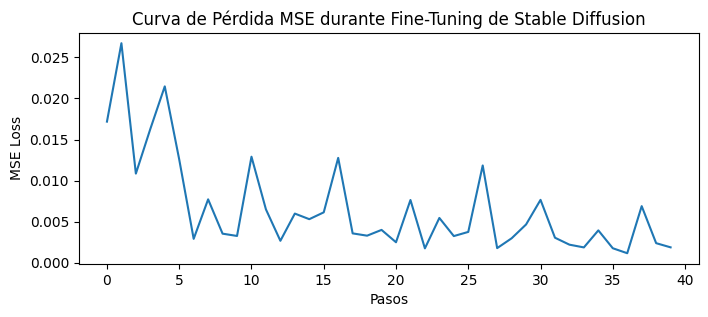

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to UNet2DConditionModel found with the prefix='unet'. This is safe to ignore if LoRA state dict didn't originally have any UNet2DConditionModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/25 [00:00<?, ?it/s]

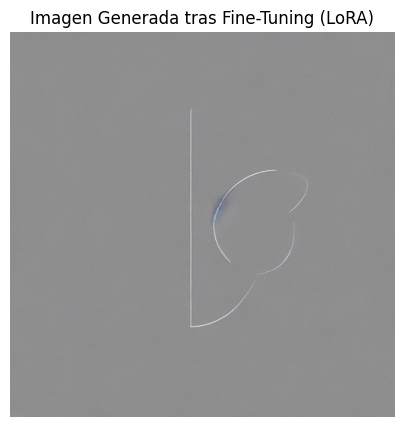

In [5]:
# CELDA 5: Inferencia y Comparación Visual
plt.figure(figsize=(8, 3))
plt.plot(losses)
plt.title("Curva de Pérdida MSE durante Fine-Tuning de Stable Diffusion")
plt.xlabel("Pasos")
plt.ylabel("MSE Loss")
plt.show()

# Cargar pipeline completo para inferencia con los pesos LoRA entrenados
pipe = StableDiffusionPipeline.from_pretrained(model_id, torch_dtype=torch.float16).to(device)
pipe.load_lora_weights("lora_weights_sks_style")

prompt_test = "a minimalist geometric portrait in sks_style, high quality"
image_out = pipe(prompt_test, num_inference_steps=25, guidance_scale=7.5).images[0]

plt.figure(figsize=(5, 5))
plt.imshow(image_out)
plt.axis("off")
plt.title("Imagen Generada tras Fine-Tuning (LoRA)")
plt.show()